In [0]:
# Import statements 
from collections import Counter
import xlrd
import pandas as pd
import numpy as np
import time
import os
import io
import matplotlib.pyplot as plt
from pyspark.sql import DataFrame
from pyspark.sql import functions as F
from pyspark.sql.functions import sum as spark_sum, col, monotonically_increasing_id,row_number,to_date,month,year
from pyspark.sql.types import StructType, StructField, StringType
from pyspark.sql.window import Window
exec(open('/Workspace/Shared/Library.py').read())

In [0]:
def createEmptySparkDf():
    schema = StructType([StructField('CODE', StringType())])
    df = spark.createDataFrame([(None,)], schema)
    empty_df = df.drop('CODE')
    return(empty_df)

def merge_dataframes(df1, df2):
    missing_cols = set(df2.columns) - set(df1.columns)
    for col in missing_cols:
        df1 = df1.withColumn(col, F.lit(None))
    missing_cols = set(df1.columns) - set(df2.columns)
    for col in missing_cols:
        df2 = df2.withColumn(col, F.lit(None))
    merged_df = df1.unionByName(df2)
    return merged_df

def finalDelivery_automapping(tables):
    if len(tables) == 0:
        print("No delivery data found.")
    delivery_df = createEmptySparkDf()
    
    for table in tables:
        # read staging table
        try:
            print("Reading table: {table}".format(table = table))
            df = spark.sql("SELECT * FROM {table_name}".format(table_name = f"staging.{table}"))
        except:
            raise ValueError(f"Table {table} not found.")
        # add columns for datastream name and attributes
        df = df.withColumn("Datastream_Name", F.lit(table))

        # Create client, product_line, and Region columns from Campaign_Name
        df = df.withColumn("Client", F.split(col("Campaign_Name"), "_").getItem(0))
        df = df.withColumn("Product_line", F.split(col("Campaign_Name"), "_").getItem(1))
        df = df.withColumn("Region", F.split(col("Campaign_Name"), "_").getItem(2))
        
        try:
            df = df.withColumn("Date", to_date(col("Date"), "yyyy-MM-dd"))
            df = df.withColumn("Year", year(col("Date")))
            df = df.withColumn("Month", month(col("Date")))
        except:
            pass
        # append table, collect all tables into one
        delivery_df = merge_dataframes(delivery_df, df)
    delivery_df = delivery_df.dropna(how = 'all')
    
    return delivery_df
  

def finalBuy_automapping(tables):
    if len(tables) == 0:
        print("No buy data found.")
    buy_df = createEmptySparkDf()
    for table in tables:
        # read staging
        try:
            df = spark.sql("SELECT * FROM {table_name}".format(table_name = f"staging.{table}"))
        except:
            continue
        # append table, collect all tables into one
        buy_df = merge_dataframes(buy_df, df)
    # Remove columns where all values are null
    non_null_counts = buy_df.select([F.count(col(c)).alias(c) for c in buy_df.columns]).collect()[0].asDict()
    cols_to_keep = [c for c in buy_df.columns if non_null_counts[c] > 0]
    buy_df = buy_df.select(*cols_to_keep)
    # Remove rows where all values are null
    buy_df = buy_df.dropna(how='all')
    return buy_df

def finalStore_automapping(tables):
    df = createEmptySparkDf()
    dma_mapping = pd.read_csv("DMA Region Mapping.csv",header = 0)
    dma_mapping = spark.createDataFrame(dma_mapping)
    for table in tables:
        try:
            df = spark.sql("SELECT * FROM {table_name}".format(table_name = f"staging.{table}"))
        except:
            print("No store data found.")
            return

    combined_df = df.join(dma_mapping, df['DMA_ID'] == dma_mapping['DMA Code'], how = 'left')
    combined_df = combined_df.drop("attributed_visits").drop("dma_code").drop("attribution_window_days").drop("DMA Name").dropna(how='all')
    
    # Aggregate row leave one row per distinct date/region 
    # Takes avg of value of different windows
    daily = (combined_df.groupBy("Date", "Region")
           .agg(F.avg("Visits").alias("avg_visits"),
                F.count("Visits").alias("n_rows"),
                F.countDistinct("Window_Day").alias("n_windows")))

    # Smooth with a 7-recorded day rolling average per region instead of taking value of single reported day --this will lose accuracy however
    # Last 7 recorded days per region (gaps skipped, not zero-filled)
    w_recorded = (Window.partitionBy("Region")
                        .orderBy("Date")
                        .rowsBetween(-6, 0))
    avg_daily_visit = daily.withColumn("avg_visits_7d_roll", F.avg("avg_visits").over(w_recorded))

    return avg_daily_visit                                                        

In [0]:
def ReadAndWrite_Step1(all_delivery_tables, all_buy_tables, all_store_tables, output_table):
    # Combine all delivery tables into one new df
    delivery_df = createEmptySparkDf()
    buy_df = createEmptySparkDf()
    store_df = createEmptySparkDf()

    delivery_df = finalDelivery_automapping(all_delivery_tables)
    buy_df = finalBuy_automapping(all_buy_tables)
    store_df = finalStore_automapping(all_store_tables)
    # print(delivery_df.count())
    buy_col_rename = buy_df.select(
        "Campaign_ID",
        F.col("Region").alias("metadata_region"),
        F.col("Client").alias("metadata_client"),
        F.col("Budget"),
        F.col("campaign_start_date"),
        F.col("campaign_end_date"),
    )
    df_combine = delivery_df.join(buy_col_rename, on="Campaign_ID", how="left")
    df_store_combine = df_combine.join(store_df, on=["Date", "Region"], how="left")
    print("total rows of Step1: ", df_store_combine.count())

    spark.sql("DROP TABLE IF EXISTS hive_metastore.staging_mid.{table_name}".format(table_name = output_table))
    df_store_combine.write.format("delta").mode("overwrite").saveAsTable(f"hive_metastore.staging_mid.{output_table}")
    print(f"Table {output_table} loaded to staging_mid")
    return

def ReadAndWrite_UnMapped(input_table, output_table):
    df = spark.sql(f"SELECT * FROM hive_metastore.staging_mid.{input_table} WHERE Currency is null and Datastream_Name like '%meta%'")
    print(df.count(), "Lines are unmapped for currency")
    spark.sql("DROP TABLE IF EXISTS hive_metastore.staging_mid.{table_name}".format(table_name = output_table))
    df.write.format("delta").mode("overwrite").option("mergeSchema", "true").saveAsTable(f"hive_metastore.staging_mid.{output_table}")
    print(f"Table {output_table} loaded to staging_mid")
    return   

def ReadAndWrite_Step2(input_table, output_table):
    df = spark.sql(f"SELECT * FROM hive_metastore.staging_mid.Automapping_Step1")
    #if want to exclude unmapped lines add where not (Currency is null and Datastream like '%meta%')
    metadata = spark.sql("SELECT * FROM hive_metastore.staging.campaign_metadata")
    ads = df

    ## Total spend and delivery per campaign
    spend = (ads.groupBy("Campaign_ID")
                .agg(F.sum("Spend").alias("total_spend"),
                    F.countDistinct("Date")))

    camp = (metadata.join(spend, "Campaign_ID", "left")
                .withColumn("flight_days",
                            F.datediff("Campaign_End_Date", "Campaign_Start_Date") + 1))
    # display(camp)
    ## Median budget per flight day by product line, from campaigns with a budget
    benchmark = (camp.filter(F.col("Budget").isNotNull())
        .withColumn("budget_per_day", F.col("Budget") / F.col("flight_days"))
        .groupBy("Product", "region")
        .agg(
            F.count("*").alias("n_campaigns"),
            F.expr("percentile(budget_per_day, 0.5)").alias("median_budget_per_day"),
            F.min("budget_per_day").alias("min_budget_per_day"),
            F.max("budget_per_day").alias("max_budget_per_day")))
    # display(benchmark)
    camp_filled = (camp
        .withColumn("Budget_original",
            F.when(F.col("Budget").cast("double") > 0, F.col("Budget").cast("double")))
        .join(benchmark.select("Product", "region", "median_budget_per_day"),
            on=["Product", "Region"], how="left")
        .withColumn("budget_source",
            F.when(F.col("Budget_original").isNotNull(), "metadata")
            .when(F.col("median_budget_per_day").isNotNull(), "benchmark")
            .otherwise("missing"))
        .withColumn("Budget",
            F.coalesce(F.col("Budget_original"),
                    F.col("median_budget_per_day") * F.col("flight_days")))
        .drop("median_budget_per_day"))

    print("Update total row of missing budget: ",camp_filled.filter(F.col("Budget_original").isNull()).count())

    budget_lookup = (camp_filled
        .select("Campaign_ID",
                F.col("Budget").alias("Budget_fill"))
        .dropDuplicates(["Campaign_ID"]))

    rows_before = df.count()
    df_updated = (df
        .withColumn("Budget_df",
            F.when(F.col("Budget").cast("double") > 0,
                F.col("Budget").cast("double")))
        .join(budget_lookup, on="Campaign_ID", how="left")
        .withColumn("Budget",
            F.coalesce(F.col("Budget_df"), F.col("Budget_fill")))
        .drop("Budget_df", "Budget_fill"))

    # Checks
    assert df_updated.count() == rows_before, "Join changed the row count"
    print("Rows with no budget after update:",
        df_updated.filter(F.col("Budget").isNull()).count())
    
    
    print("total rows of Step2: ", df_updated.count())
    spark.sql("DROP TABLE IF EXISTS hive_metastore.staging_mid.{table_name}".format(table_name = output_table))
    df_updated.write.format("delta").mode("overwrite").option("mergeSchema", "true").saveAsTable(f"hive_metastore.staging_mid.{output_table}")
    print(f"Table {output_table} loaded to staging_mid")
    return

In [0]:
def main():
  config_step1 = {
        "delivery_table":["google_ads_daily","meta_ads_daily"],
        "buy_table": ['campaign_metadata'],
        "store_table": ['store_visits'],
        "output_table_name": "Automapping_Step1",
    }
  config_unmapped ={
      "input_table_name": "Automapping_Step1",
      "output_table_name": "Automapping_unmapped",
  }
  config_step2 = {
        "input_table_name": "Automapping_Step1",
        "output_table_name": "Automapping_Step2",
    }
  time0 = time.time()
  ReadAndWrite_Step1(
    all_delivery_tables  = config_step1["delivery_table"],
    all_buy_tables = config_step1["buy_table"],
    all_store_tables = config_step1["store_table"],
    output_table = config_step1["output_table_name"],)
  time1 = time.time()
  print(
      f"Step 1 completes in {time1 - time0:.2f} seconds"
  )
  ReadAndWrite_UnMapped(
    input_table = config_unmapped["input_table_name"],
    output_table = config_unmapped["output_table_name"],
  )
  time2 = time.time()
  print(
      f"Step Unmapped completes in {time2 - time1:.2f} seconds"
  )
  ReadAndWrite_Step2(
    input_table = config_step2["input_table_name"],
    output_table = config_step2["output_table_name"],
  )
  time3 = time.time()
  print(
      f"Step 2 completes in {time3 - time2:.2f} seconds"
  )
 
  

In [0]:
main()

Reading table: google_ads_daily
Reading table: meta_ads_daily
total rows of Step1:  4631
Table Automapping_Step1 loaded to staging_mid
Step 1 completes in 44.83 seconds
133 Lines are unmapped for currency
Table Automapping_unmapped loaded to staging_mid
Step Unmapped completes in 56.32 seconds
Update total row of missing budget:  9
Rows with no budget after update: 0
total rows of Step2:  4631
Table Automapping_Step2 loaded to staging_mid
Step 2 completes in 9.80 seconds


### Q1, Blended CPC

In [0]:
%sql
-- Campaign_ID = '1251' and '1156' appears to be no line matching
SELECT
    
    Datastream_Name as Platform,
    Client,
    Year,
    Month,
    SUM(Spend)        AS total_spend,
    SUM(Conversions)  AS total_conversions,
    SUM(Spend) / NULLIF(SUM(Conversions), 0) AS blended_cost_per_conversion
FROM hive_metastore.staging_mid.automapping_step2
WHERE Spend IS NOT NULL
  AND Conversions IS NOT NULL
GROUP BY Datastream_Name,Client, Year, Month
ORDER BY Datastream_Name,Client, Year, Month;

Platform,Client,Year,Month,total_spend,total_conversions,blended_cost_per_conversion
google_ads_daily,HomeBase,2026,1,68446.634197,1659.9299999999996,41.23465097745087
google_ads_daily,HomeBase,2026,2,448983.49332799984,10217.450000000003,43.94281286700691
google_ads_daily,HomeBase,2026,3,696970.1678120003,16250.75999999999,42.888466004789976
google_ads_daily,HomeBase,2026,4,532033.1527569998,12464.320000000009,42.6844908311885
google_ads_daily,HomeBase,2026,5,266880.13812300004,5832.859999999999,45.75459347952807
google_ads_daily,HomeBase,2026,6,145024.55560899997,3116.45,46.53517804200291
meta_ads_daily,HomeBase,2026,1,96208.58179999999,2051.0,46.90813349585567
meta_ads_daily,HomeBase,2026,2,891481.6422,18197.0,48.99058318404133
meta_ads_daily,HomeBase,2026,3,1608259.540999999,34388.0,46.76804527742233
meta_ads_daily,HomeBase,2026,4,1282158.4368000017,27534.0,46.56637018958385


### Q2, WOW spend growth

In [0]:
%sql

WITH bounds AS (
    SELECT MAX(Date) AS max_date
    FROM staging_mid.Automapping_step2
),
anchor AS (
    SELECT
        CASE
            WHEN max_date = date_add(trunc(max_date, 'WEEK'), 6)
                THEN trunc(max_date, 'WEEK')
            ELSE date_add(trunc(max_date, 'WEEK'), -7)
        END AS last_week
    FROM bounds
),
weekly AS (
    SELECT
        Campaign_ID,
        MAX(Campaign_Name)  AS Campaign_Name,
        trunc(Date, 'WEEK') AS week_start,
        SUM(Spend)          AS weekly_spend
    FROM staging_mid.Automapping_step2
    WHERE Spend IS NOT NULL
    GROUP BY Campaign_ID, trunc(Date, 'WEEK')
),
wow AS (
    SELECT
        Campaign_ID,
        Campaign_Name,
        week_start,
        weekly_spend,
        LAG(weekly_spend) OVER (PARTITION BY Campaign_ID ORDER BY week_start) AS prev_week_spend,
        LAG(week_start)   OVER (PARTITION BY Campaign_ID ORDER BY week_start) AS prev_week_start
    FROM weekly
),
growth AS (
    SELECT
        w.Campaign_ID,
        w.Campaign_Name,
        w.week_start,
        w.weekly_spend,
        w.prev_week_spend,
        -- NULLIF avoids division by zero; negative growth is kept as is
        (w.weekly_spend - w.prev_week_spend) / NULLIF(w.prev_week_spend, 0) AS wow_growth
    FROM wow w
    CROSS JOIN anchor a
    WHERE w.week_start BETWEEN date_add(a.last_week, -21) AND a.last_week
      AND datediff(w.week_start, w.prev_week_start) = 7   -- previous week must exist
),
summary AS (
    SELECT
        g.Campaign_ID,
        MAX(g.Campaign_Name)                                                  AS Campaign_Name,
        COUNT(g.wow_growth)                                                   AS weeks_with_growth,
        ROUND(AVG(g.wow_growth) * 100, 1)                                     AS avg_wow_growth_pct,
        MAX(CASE WHEN g.week_start = a.last_week THEN g.prev_week_spend END)  AS prev_week_spend,
        MAX(CASE WHEN g.week_start = a.last_week THEN g.weekly_spend END)     AS latest_week_spend
    FROM growth g
    CROSS JOIN anchor a
    GROUP BY g.Campaign_ID
),
ranked AS (
    SELECT
        *,
        ROW_NUMBER() OVER (ORDER BY avg_wow_growth_pct DESC) AS rank_up,
        ROW_NUMBER() OVER (ORDER BY avg_wow_growth_pct ASC)  AS rank_down
    FROM summary
)
SELECT
    Campaign_ID,
    Campaign_Name,
    weeks_with_growth,
    avg_wow_growth_pct,
    CASE WHEN avg_wow_growth_pct < 0 THEN 'Decline' ELSE 'Growth' END AS direction,
    prev_week_spend,
    latest_week_spend
FROM ranked
WHERE rank_up <= 10 OR rank_down <= 10
ORDER BY avg_wow_growth_pct DESC;

Campaign_ID,Campaign_Name,weeks_with_growth,avg_wow_growth_pct,direction,prev_week_spend,latest_week_spend
1033,HomeBase_Seasonal_National_Search,4,9.4,Growth,52677.515119,37431.571975
1283,HomeBase_Appliances_National_Search,4,-15.5,Decline,52446.801815,6553.616635
1203,HomeBase_Appliances_National_Search,3,-19.7,Decline,null,null
1174,HomeBase_Appliances_National_Search,3,-21.2,Decline,null,null


### Q3, relation Attribution windows vs weekly Spend

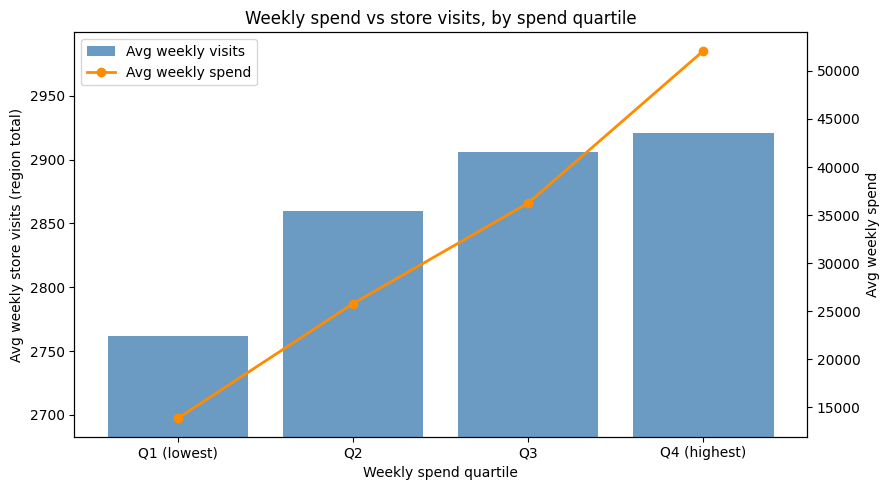

In [0]:

base = (spark.table("hive_metastore.staging_mid.Automapping_Step2")
        .filter(F.col("Spend").isNotNull()
                & F.col("avg_visits").isNotNull())
        .withColumn("week_start", F.trunc("Date", "WEEK")))

# Weekly spend per campaign, region, and week (sum of daily rows)
campaign_week = (base.groupBy("Campaign_ID", "Region", "week_start")
                     .agg(F.sum("Spend").alias("weekly_spend")))

# Weekly visits per region: count each region-day once, since it repeats on every ad row
visit_week = (base.select("Region", "Date", "week_start", "avg_visits").distinct()
                  .groupBy("Region", "week_start")
                  .agg(F.sum("avg_visits").alias("weekly_visits")))

joined = campaign_week.join(visit_week, on=["Region", "week_start"], how="inner")

pdf = joined.toPandas()

# Bin campaign-weeks into spend quartiles
pdf["spend_quartile"] = pd.qcut(
    pdf["weekly_spend"], 4,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    duplicates="drop"
)

summary = (pdf.groupby("spend_quartile", observed=True)
              .agg(avg_spend=("weekly_spend", "mean"),
                   avg_visits=("weekly_visits", "mean"),
                   n_weeks=("weekly_spend", "size"))
              .reset_index())

x = list(range(len(summary)))
fig, ax = plt.subplots(figsize=(9, 5))
visits = summary["avg_visits"].values
v_min, v_max = visits.min(), visits.max()
pad = max((v_max - v_min) * 0.5, v_max * 0.01)   # room around the bars

ax.set_ylim(v_min - pad, v_max + pad)           # zoom the visits axis
# Bars: average weekly store visits per spend quartile
ax.bar(x, summary["avg_visits"], color="steelblue", alpha=0.8,
       label="Avg weekly visits")
       
ax.set_ylabel("Avg weekly store visits (region total)")
ax.set_xticks(x)
ax.set_xticklabels(summary["spend_quartile"])
ax.set_xlabel("Weekly spend quartile")

# Line: average weekly spend per quartile, on a secondary axis
ax2 = ax.twinx()
ax2.plot(x, summary["avg_spend"], color="darkorange",
         marker="o", linewidth=2, label="Avg weekly spend")
ax2.set_ylabel("Avg weekly spend")

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")

ax.set_title("Weekly spend vs store visits, by spend quartile")
plt.tight_layout()
plt.show()

### Q4 Campaign overspend

In [0]:
%sql

WITH campaign_totals AS (
    SELECT
        Campaign_ID,
        MAX(Campaign_Name)                                   AS Campaign_Name,
        MAX(Budget)                                          AS stated_budget,
        MIN(Date)                                            AS first_delivery_date,
        MAX(Date)                                            AS last_delivery_date,
        SUM(Spend)                                           AS spend,
        SUM(CASE WHEN Date > CAST(campaign_end_date AS DATE) THEN Spend ELSE 0 END) AS spend_after_end_date
    FROM staging_mid.Automapping_step2
    WHERE Budget IS NOT NULL
      AND Budget > 0
      AND Spend IS NOT NULL
    GROUP BY Campaign_ID
)
SELECT
    Campaign_ID,
    Campaign_Name,
    stated_budget,
    spend,
    spend - stated_budget                 AS overspend_usd,
    ROUND(spend / stated_budget, 3)       AS pct_of_budget,
    spend_after_end_date,
    first_delivery_date,
    last_delivery_date
FROM campaign_totals
WHERE spend > stated_budget
ORDER BY pct_of_budget DESC;

Campaign_ID,Campaign_Name,stated_budget,spend,overspend_usd,pct_of_budget,spend_after_end_date,first_delivery_date,last_delivery_date
1174,HomeBase_Appliances_National_Search,29177.6052631579,858293.8526350008,829116.247371843,29.416,0.0,2026-03-13,2026-06-10
1283,HomeBase_Appliances_National_Search,26584.040350877196,504819.09756999987,478235.05721912265,18.99,0.0,2026-03-26,2026-06-15
1090,HomeBase_Appliances_National_Q1_v2,36958.3,427124.2722000002,390165.9722000002,11.557,0.0,2026-02-18,2026-04-15
1203,HomeBase_Appliances_National_Search,24638.866666666672,256541.89684899998,231903.0301823333,10.412,0.0,2026-03-29,2026-06-12
1274,HomeBase_Appliances_National_Search,10374.259649122809,100724.71271299999,90350.45306387718,9.709,0.0,2026-01-31,2026-03-03
1033,HomeBase_Seasonal_National_Search,71635.18,558872.0865249999,487236.90652499994,7.802,0.0,2026-03-25,2026-06-23
1051,HomeBase_Appliances_National_Search,52512.63,386381.5942870001,333868.96428700007,7.358,0.0,2026-02-24,2026-04-29
1082,HomeBase_Seasonal_National_Search,21186.29,138286.756755,117100.466755,6.527,0.0,2026-04-01,2026-04-30
1241,HomeBase_Seasonal_National_Search,64216.606216117216,417403.03998599993,353186.4337698827,6.5,0.0,2026-01-23,2026-04-18
1267,HomeBase_Furniture_National_Search,133627.45,645372.499698,511745.049698,4.83,0.0,2026-02-11,2026-05-05
